# Modelo 2 · Efecto del cambio de precio
## Notebook 2: las tareas, las métricas y el baseline

| Tarea | Pregunta | Métrica |
|---|---|---|
| **1. Pronóstico** | ¿Cuántas unidades venderá el SKU la semana *t*, con el precio planificado para *t*? | **WAPE** = error absoluto ÷ unidades reales (menos es mejor) |
| **2. Escenarios** (la que importa) | Si el precio cambia −15 %, −5 %, +5 % o +15 %, ¿cuánto cambian las unidades? ¿Conviene, es decir, sube la contribución = unidades × (precio − costo)? | **Error medio del cambio de unidades**, en puntos porcentuales (menos es mejor) |

**Por qué la métrica principal es el error del cambio de unidades y no "conviene":** con márgenes de 35–45 % y elasticidades cercanas a −1, subir el precio casi siempre sube la contribución en el corto plazo. "Conviene" se acierta ~98 % con cualquier modelo; lo que distingue a un buen modelo es **cuánto** cambia la venta.

**Cortes de tiempo:** entrenamiento 2023–2024 · validación ene–jun 2025 · prueba jul–dic 2025 (la guarda Pycca, con la respuesta exacta de cada escenario).

**El baseline:** **una elasticidad por división, medida tal cual** (con efectos fijos de SKU y semana), sin separar promoción, temporada, liquidación ni competencia.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.dates as mdates
warnings.filterwarnings('ignore')
RAIZ = Path('..') if Path('../comun.py').exists() else Path('.')        # repo (notebooks/) o paquete de ESPOL
sys.path.insert(0, str(RAIZ)); sys.path.insert(0, '.')
import estilo; estilo.aplicar()
from estilo import AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, TINTA2, GRIS, SERIES, pie
from comun import CORTES, cargar
DATOS = RAIZ / 'datos'
HAY_VERDAD = (DATOS / 'verdad' / 'parametros_sku.parquet').exists()     # solo en Pycca (la elasticidad verdadera no se entrega)
pd.set_option('display.width', 160)
import baseline as B
from comun import CAMBIOS, armar_escenarios, metricas_escenarios, metricas_pronostico, verdad_escenarios, wape
CORTES_EVAL = [k for k in ('validacion', 'prueba') if ((B.v.semana >= CORTES[k][0]) & (B.v.semana <= CORTES[k][1])).any()]
print('Cortes disponibles para evaluar:', CORTES_EVAL)

Cortes disponibles para evaluar: ['validacion']


### 1. Ajustar el baseline y pronosticar

In [2]:
res, pron, eps_corte = {}, {}, {}
for k in CORTES_EVAL:
    hasta = CORTES['entrenamiento'][1] if k == 'validacion' else CORTES['validacion'][1]   # para la prueba se reentrena hasta junio 2025
    eps, est = B.ajustar(hasta)
    x = B.pronosticar(*CORTES[k], eps, est)
    pron[k], eps_corte[k] = x, eps
    res[k] = metricas_pronostico(x.unidades, x.pred)
pd.DataFrame(res).T

,WAPE,sesgo
validacion,0.5222,0.0257


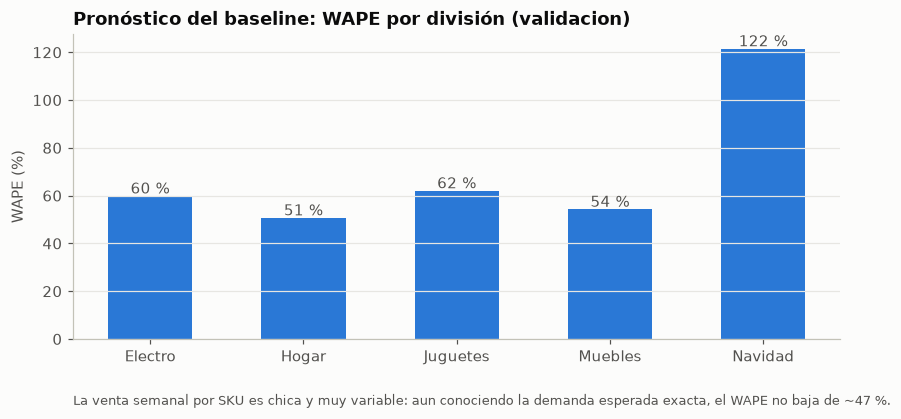

In [3]:
k = CORTES_EVAL[-1]; x = pron[k]
fig, ax = plt.subplots(figsize=(9, 3.6))
w = x.groupby('division').apply(lambda g: wape(g.unidades, g.pred)) * 100
ax.bar([d.title() for d in w.index], w.values, color=AZUL, width=0.55)
for i, val in enumerate(w.values):
    ax.text(i, val + 1, f'{val:.0f} %', ha='center', color=TINTA2)
ax.set_title(f'Pronóstico del baseline: WAPE por división ({k})'); ax.set_ylabel('WAPE (%)'); ax.grid(axis='x', visible=False)
pie(ax, 'La venta semanal por SKU es chica y muy variable: aun conociendo la demanda esperada exacta, el WAPE no baja de ~47 %.')
plt.show()

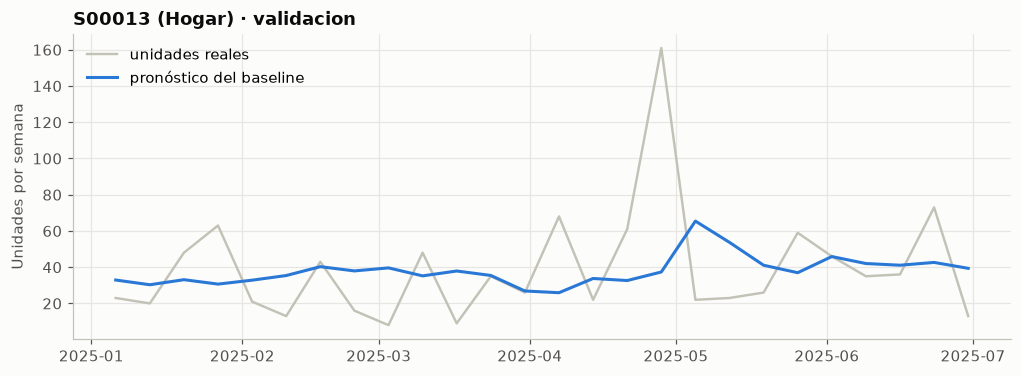

In [4]:
top = x.groupby('sku').unidades.sum().sort_values()
s_ej = top.index[int(len(top) * 0.9)]
g = x[x.sku == s_ej]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(g.semana, g.unidades, color=GRIS, lw=1.6, label='unidades reales')
ax.plot(g.semana, g.pred, color=AZUL, label='pronóstico del baseline')
ax.set_title(f'{s_ej} ({g.division.iloc[0].title()}) · {k}'); ax.set_ylabel('Unidades por semana'); ax.legend(loc='upper left')
plt.show()

### 2. La elasticidad que usa el baseline

Una sola por división, medida "tal cual". En el notebook 1 se vio que esa medición mezcla el precio con la publicidad de las promociones: sale más negativa de lo que es.

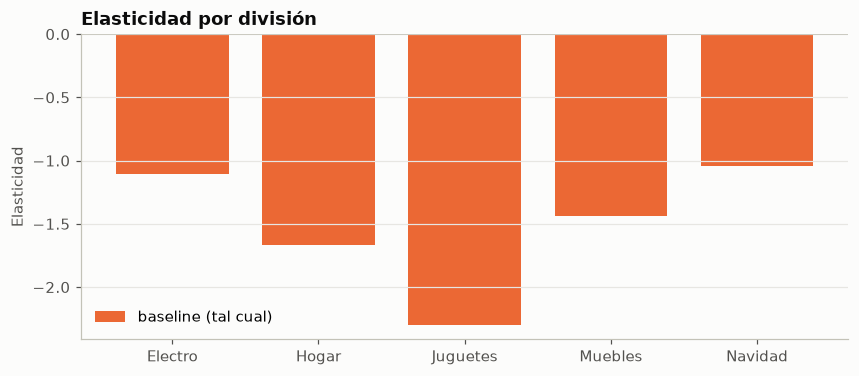

,baseline (tal cual)
ELECTRO,-1.109
HOGAR,-1.667
JUGUETES,-2.296
MUEBLES,-1.438
NAVIDAD,-1.042


In [5]:
eb = pd.Series(eps_corte[CORTES_EVAL[-1]]).rename('baseline (tal cual)')
tab = eb.to_frame()
if HAY_VERDAD:
    tab['verdadera (promedio)'] = pd.read_parquet(DATOS / 'verdad' / 'parametros_sku.parquet').groupby('division').elasticidad.mean()
fig, ax = plt.subplots(figsize=(9, 3.6))
xs = np.arange(len(tab)); w = 0.8 / tab.shape[1]
for i, (c, col) in enumerate(zip(tab.columns, [NARANJA, AQUA])):
    ax.bar(xs + (i - (tab.shape[1] - 1) / 2) * w, tab[c], width=w - 0.03, color=col, label=c)
ax.set_xticks(xs, [d.title() for d in tab.index]); ax.axhline(0, color=GRIS, lw=1); ax.grid(axis='x', visible=False)
ax.set_ylabel('Elasticidad'); ax.legend(loc='lower left'); ax.set_title('Elasticidad por división')
plt.show()
tab.round(3)

### 3. Escenarios: ¿qué pasa si cambio el precio?

Para cada caso (SKU y semana sin promoción) se proponen cuatro precios. El baseline predice el cambio de unidades con su elasticidad de división: `(precio nuevo / precio actual) ^ elasticidad − 1`.

In [6]:
if (DATOS / 'escenarios_prueba.csv').exists():
    esc = pd.read_csv(DATOS / 'escenarios_prueba.csv', parse_dates=['semana'])
else:
    esc = armar_escenarios(B.v)
div = B.v.drop_duplicates('sku').set_index('sku').division
e = esc.sku.map(div).map(eps_corte[CORTES_EVAL[-1]])
pred = esc.assign(cambio_unidades=(esc.precio_propuesto / esc.precio_actual) ** e - 1)
pred['conviene'] = (1 + pred.cambio_unidades) * (pred.precio_propuesto - pred.costo_unitario) > (pred.precio_actual - pred.costo_unitario)
print('Así se entrega cada escenario (una fila por caso y cambio):')
pred[['caso', 'sku', 'semana', 'precio_actual', 'cambio', 'precio_propuesto', 'costo_unitario', 'cambio_unidades', 'conviene']].head(8).round(3)

Así se entrega cada escenario (una fila por caso y cambio):


,caso,sku,semana,precio_actual,cambio,precio_propuesto,costo_unitario,cambio_unidades,conviene
0,0,S00183,2025-12-01,4.28,-0.15,3.64,1.76,0.310,False
1,0,S00183,2025-12-01,4.28,-0.05,4.07,1.76,0.087,False
2,0,S00183,2025-12-01,4.28,0.05,4.49,1.76,-0.077,True
3,0,S00183,2025-12-01,4.28,0.15,4.92,1.76,-0.207,False
4,1,S00140,2025-10-13,8.04,-0.15,6.83,4.40,0.313,False
5,1,S00140,2025-10-13,8.04,-0.05,7.64,4.40,0.089,False
6,1,S00140,2025-10-13,8.04,0.05,8.44,4.40,-0.078,True
7,1,S00140,2025-10-13,8.04,0.15,9.25,4.40,-0.208,True


La respuesta de los escenarios la guarda Pycca: aquí se arma el archivo que se entrega.


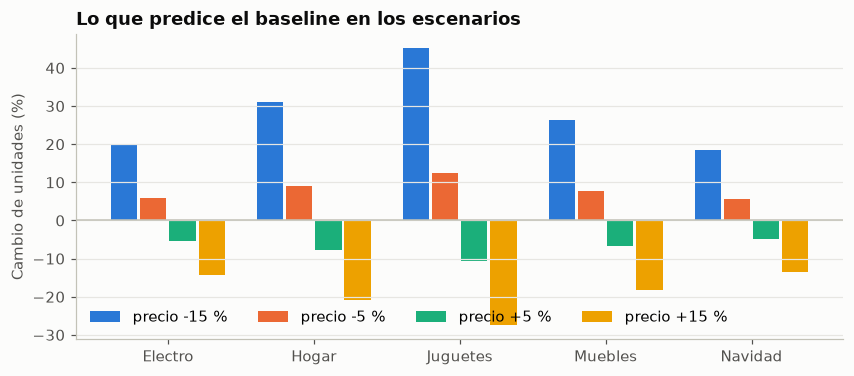

In [7]:
if HAY_VERDAD:
    ver = verdad_escenarios(esc, DATOS)
    print('Métricas del baseline en la prueba:', metricas_escenarios(pred, ver))
    m = ver.merge(pred[['caso', 'cambio', 'cambio_unidades']], on=['caso', 'cambio'])
    fig, axs = plt.subplots(1, 2, figsize=(11, 4.2), sharey=False)
    for ax, c in zip(axs, (-0.15, 0.15)):
        mm = m[m.cambio == c]
        ax.scatter(100 * mm.cambio_unidades_real, 100 * mm.cambio_unidades, s=14, color=AZUL, alpha=0.6, edgecolor='none')
        lo, hi = 100 * min(mm.cambio_unidades_real.min(), mm.cambio_unidades.min()), 100 * max(mm.cambio_unidades_real.max(), mm.cambio_unidades.max())
        ax.plot([lo, hi], [lo, hi], color=GRIS, ls='--', lw=1)
        ax.set_title(f'Precio {int(c * 100):+d} %: cambio de unidades'); ax.set_xlabel('Verdadero (%)'); ax.set_ylabel('Baseline (%)')
    plt.tight_layout(); plt.show()
else:
    print('La respuesta de los escenarios la guarda Pycca: aquí se arma el archivo que se entrega.')
    fig, ax = plt.subplots(figsize=(9, 3.6))
    t = pred.groupby([pred.sku.map(div), 'cambio']).cambio_unidades.median().unstack() * 100
    xs = np.arange(len(t)); w = 0.2
    for i, (c, col) in enumerate(zip(t.columns, SERIES)):
        ax.bar(xs + (i - 1.5) * w, t[c], width=w - 0.02, color=col, label=f'precio {int(c * 100):+d} %')
    ax.set_xticks(xs, [d.title() for d in t.index]); ax.axhline(0, color=GRIS, lw=1); ax.grid(axis='x', visible=False)
    ax.set_ylabel('Cambio de unidades (%)'); ax.legend(ncol=4, loc='lower left'); ax.set_title('Lo que predice el baseline en los escenarios')
    plt.show()

## Resumen y dónde mejorar

- **Métrica a seguir:** el **error del cambio de unidades** en los escenarios (el baseline se equivoca 5,8 puntos en la prueba). El WAPE del pronóstico se reporta, pero tiene poco margen (~47 % es el piso por el ruido).
- **Dónde mejorar:**
  1. separar el efecto de la promoción del efecto del precio;
  2. controlar la estacionalidad por división y la competencia;
  3. no confundir la liquidación de fin de vida con elasticidad;
  4. estimar la elasticidad **por SKU**, acercándola a la de su división cuando hay pocos datos (modelos jerárquicos o bayesianos).